# 02 · Suavizamiento exponencial y modelos ARIMA

**Objetivo:** pronosticar 11 años de CO₂ con modelos de complejidad creciente, todos contra los
mismos baselines, y comparar implementaciones propias con statsmodels.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
co2 = (
    sm.datasets.co2.load_pandas().data["co2"].resample("MS").mean().interpolate()
)  # mensual, 1958–2001
from applied_ts.autocorrelation import difference, undifference
from applied_ts.evaluation import mae, mase, rmse
from applied_ts.models import drift, fit_ar, holt_winters, naive, seasonal_naive
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

train, test = co2[:"1990-12"], co2["1991-01":]
y_tr, h = train.to_numpy(), len(test)
print(f"train {len(train)} meses, test {h} meses")

train 394 meses, test 132 meses


## 1. Baselines

In [2]:
forecasts = {
    "naive": naive(y_tr, h),
    "seasonal naive": seasonal_naive(y_tr, h, 12),
    "drift": drift(y_tr, h),
}

## 2. Holt–Winters: propio vs. statsmodels

Nivel, tendencia y estacionalidad aditivos, parámetros por mínimos cuadrados de errores a un paso.

In [3]:
hw = holt_winters(y_tr, trend=True, seasonal_period=12)
print(f"propio:      α = {hw.alpha:.3f}, β = {hw.beta:.3f}, γ = {hw.gamma:.3f}")
hw_sm = ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=12).fit()
p = hw_sm.params
a, b, g = p["smoothing_level"], p["smoothing_trend"], p["smoothing_seasonal"]
print(f"statsmodels: α = {a:.3f}, β = {b:.3f}, γ = {g:.3f}")
forecasts["Holt–Winters (propio)"] = hw.forecast(h)
forecasts["Holt–Winters (statsmodels)"] = hw_sm.forecast(h)

propio:      α = 0.498, β = 0.014, γ = 0.406
statsmodels: α = 0.700, β = 0.000, γ = 0.000


## 3. AR sobre la serie diferenciada

∇∇₁₂ la vuelve estacionaria (notebook 01). Ajustamos un AR(p) por mínimos cuadrados sobre esa
serie y deshacemos las diferencias para volver a ppm.

In [4]:
d12 = difference(y_tr, 12)
dd = difference(d12, 1)
ar = fit_ar(dd, 3)
dd_fc = ar.forecast(dd, h)
d12_fc = undifference(dd_fc, d12, 1)
forecasts["AR(3) sobre ∇∇₁₂ (propio)"] = undifference(d12_fc, y_tr, 12)
print("coeficientes AR:", np.round(ar.coefs, 3))

coeficientes AR: [-0.367 -0.153 -0.19 ]


## 4. SARIMA (statsmodels)

SARIMA(1,1,1)(0,1,1)₁₂, el modelo “aerolínea” extendido: diferencia regular y estacional, más
términos AR y MA. Da además intervalos de predicción.

In [5]:
sarima = SARIMAX(y_tr, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
fc = sarima.get_forecast(h)
forecasts["SARIMA(1,1,1)(0,1,1)₁₂"] = fc.predicted_mean
interval = fc.conf_int(alpha=0.05)
inside = np.mean((test.to_numpy() >= interval[:, 0]) & (test.to_numpy() <= interval[:, 1]))
print(f"cobertura del intervalo del 95 % en test: {inside:.0%}")

cobertura del intervalo del 95 % en test: 97%


## 5. Comparación

                    modelo   MAE   RMSE  MASE
    SARIMA(1,1,1)(0,1,1)₁₂ 0.840  1.018 0.687
 AR(3) sobre ∇∇₁₂ (propio) 0.877  1.022 0.717
     Holt–Winters (propio) 0.928  1.097 0.759
Holt–Winters (statsmodels) 1.381  1.739 1.129
                     drift 2.878  3.427 2.353
            seasonal naive 8.580 10.051 7.014
                     naive 8.685 10.231 7.100


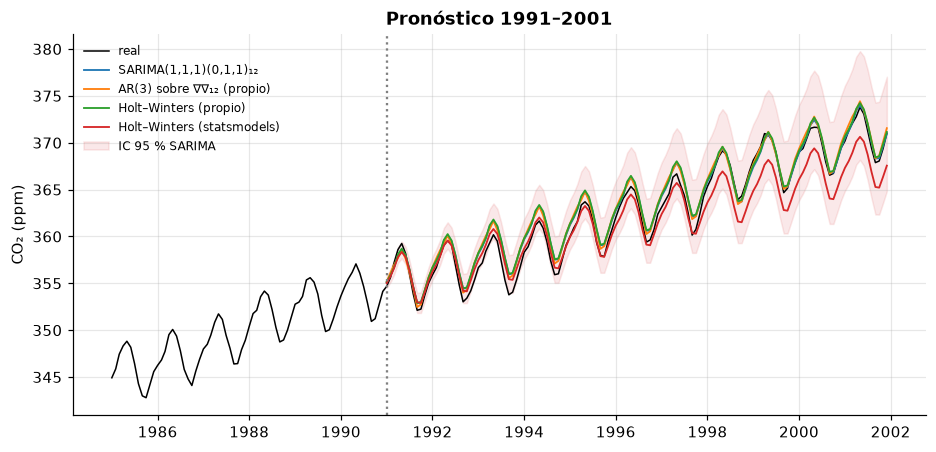

In [6]:
rows = []
for name, f in forecasts.items():
    rows.append((name, mae(test, f), rmse(test, f), mase(test, f, y_tr, 12)))
table = pd.DataFrame(rows, columns=["modelo", "MAE", "RMSE", "MASE"]).sort_values("MASE")
print(table.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(co2["1985":].index, co2["1985":], color="k", lw=1, label="real")
for name in table["modelo"].head(4):
    ax.plot(test.index, forecasts[name], lw=1.2, label=name)
ax.fill_between(
    test.index, interval[:, 0], interval[:, 1], color="C3", alpha=0.1, label="IC 95 % SARIMA"
)
ax.axvline(test.index[0], color="gray", ls=":")
ax.set(ylabel="CO₂ (ppm)", title="Pronóstico 1991–2001")
ax.legend(fontsize=8);

- **SARIMA gana** (MASE 0.69), seguido de cerca por el AR(3) propio sobre la serie diferenciada:
  ambos modelan la serie después de ∇∇₁₂, que es lo que sugería la ACF del notebook 01. El
  intervalo del 95 % de SARIMA cubre el 97 % del test.
- **Nuestro Holt–Winters supera al de statsmodels** aquí (0.76 frente a 1.13), pero no por ser mejor
  en general: el optimizador de statsmodels terminó en el borde β = γ = 0, es decir, nunca
  actualiza la tendencia ni la estacionalidad iniciales. Revisar los parámetros ajustados, no
  solo el error, evita conclusiones equivocadas sobre un método.
- **Con 11 años de horizonte y tendencia fuerte, los baselines sin tendencia fracasan** (naive y
  seasonal naive, MASE ≈ 7). El baseline adecuado depende del horizonte: “drift” al menos sigue la
  pendiente.

## Para llevar

- Siempre reportar baselines, elegidos según el horizonte: en horizontes cortos “seasonal naive”
  es difícil de batir; en horizontes largos con tendencia, hace falta al menos “drift”.
- Holt–Winters y SARIMA capturan tendencia y estacionalidad con pocos parámetros.
- Los intervalos de predicción importan tanto como el punto: crecen con el horizonte.